# E119: where do the teacher-trained decompositions carry their gain on the trigger tasks?

**The answer.** The regeneration did not reproduce the original behaviour within 0.05, so the run stopped. The emoticon task's Pile-text copy of the Adam fine-tune reached a target probability of 0.74, where the original run read 0.90. The other eleven copies reproduced within 0.016. Read provisionally, eight of those eleven land in neither corner, as their fine-tunes do, and three land in the re-switching corner. All three are Pile-text copies, and two of them sit where their own fine-tune reads neither.

Full record, scoring and provenance: `reports/analyses/2026-11-06_analysis_e119-teacher-route-split-triggers.md`.


## What we were trying to test

Teacher training copies a fine-tuned model into the decomposition: only the subcomponents' U and V train, for 1000 steps, on the KL divergence from the fine-tuned model, with Γ and Δ frozen. Arm A trains on the task's own windows; arm B on Pile text, which never shows the task. The original run made twelve such copies, from an SGD and an Adam fine-tune on each of three trigger tasks, and saved none. This job regenerated them with the same seeds and stopped if any copy's held-out target probability fell more than 0.05 from the original's.

Each state's gain at the trigger, the rise in the target's log-odds from the original model, is split two ways:

- the **re-switching share** $r$: keep the original subcomponents, take Γ's masks from the new state, and see what share of the gain that alone gives. 0 means the masks change nothing; 1 means switching carries everything.
- the **masked-off share**: the share of the gain carried by subcomponents the mask turns off. 0 means none; 1 means all.

The labels are the copy-versus-map experiment's filed lines: re-switching if $r \ge 0.6$ with a masked-off share at most 0.25; masked-off if the masked-off share is at least 0.5 with $r \le 0.35$; neither otherwise. A state with under half its teacher's gain is unreadable. Each copy sits beside its fine-tune, read by the least-squares split. In that earlier experiment, copy tables read re-switching and random maps masked-off: the grey points in the figure.

We expected every copy to read neither, since the fine-tunes' re-switching shares lie between the lines, and each copy to keep its fine-tune's label.


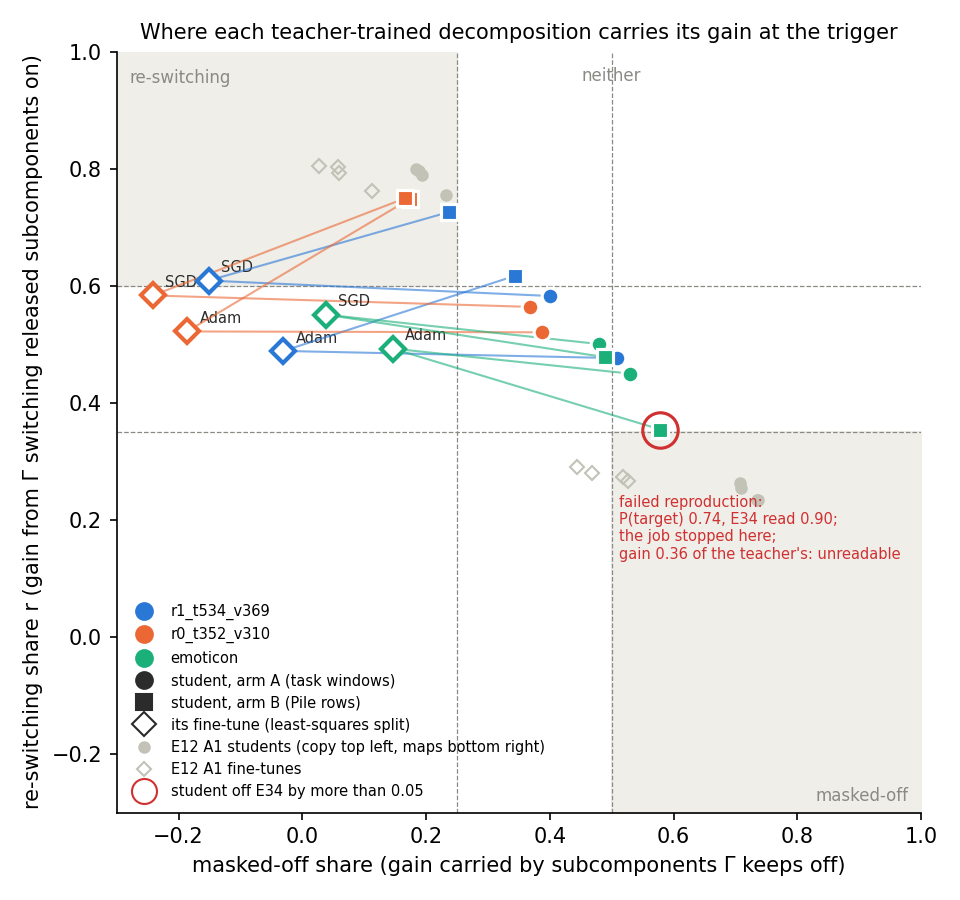

In [1]:
from IPython.display import Image

Image("../experiments/teacher_route_split/figures/route_labels.png", width=640)


## Did the regeneration reproduce the original run, and where do the copies land?

**Reading it.** The regeneration failed on one of twelve copies. The red ring is the emoticon task's Pile-text copy of the Adam fine-tune: its target probability was 0.744 against the original's 0.902. That fall is three times the tolerance and five times the largest change a second batch order made in the original run. The job stopped there by its own rule. The six fine-tunes and the other eleven copies all reproduced within 0.016. The cause of the miss is not known; this job ran on an L40, the original on an H100, and that difference is untested.

Read provisionally, the six task-text copies, the circles, all land in neither corner and stay close to their fine-tune on the re-switching axis. The Pile-text copies, the squares, sit higher on that axis than the task-text copies on both key rules, but not on the emoticon task. Three of them cross into the re-switching corner. The fine-tunes' masked-off shares, the open diamonds, are negative on both key rules and positive on the emoticon task.


In [2]:
import json
from pathlib import Path

from IPython.display import Markdown

R = Path("../experiments/teacher_route_split/results")
rows = ["| task, teacher, arm | copy P / original P | re-switching share | masked-off share | copy label / fine-tune label |", "|---|---|---|---|---|"]
for task in ("r1_t534_v369", "r0_t352_v310", "emoticon"):
    out = json.loads((R / f"teacher_route_split_{task}.json").read_text())
    e34 = json.loads(Path(f"../experiments/teacher_training/results/teacher_training_{task}.json").read_text())["teachers"]
    for name, s in out["students"].items():
        opt, arm = name.split("_")
        sh = s["a"]["shares"]
        rows.append(f"| {task}, {opt}, {arm} | {s['p_target']:.3f} / {e34[opt][arm]['1000']['p_target']:.3f} | {sh['r']:.3f} | "
                    f"{sh['e_gate']:.3f} | {s['label']} / {s['ft_label']} |")
Markdown("\n".join(rows))


| task, teacher, arm | copy P / original P | re-switching share | masked-off share | copy label / fine-tune label |
|---|---|---|---|---|
| r1_t534_v369, adam, A | 0.995 / 0.994 | 0.476 | 0.509 | neither / neither |
| r1_t534_v369, adam, B | 0.981 / 0.983 | 0.617 | 0.344 | neither / neither |
| r1_t534_v369, sgd, A | 0.996 / 0.996 | 0.582 | 0.400 | neither / re-switching |
| r1_t534_v369, sgd, B | 0.984 / 0.974 | 0.726 | 0.237 | re-switching / re-switching |
| r0_t352_v310, adam, A | 0.925 / 0.921 | 0.520 | 0.388 | neither / neither |
| r0_t352_v310, adam, B | 0.896 / 0.908 | 0.748 | 0.174 | re-switching / neither |
| r0_t352_v310, sgd, A | 0.944 / 0.942 | 0.564 | 0.368 | neither / neither |
| r0_t352_v310, sgd, B | 0.935 / 0.919 | 0.749 | 0.166 | re-switching / neither |
| emoticon, adam, A | 0.997 / 0.997 | 0.450 | 0.530 | neither / neither |
| emoticon, adam, B | 0.744 / 0.902 | 0.354 | 0.579 | unreadable / neither |
| emoticon, sgd, A | 0.998 / 0.999 | 0.500 | 0.480 | neither / neither |
| emoticon, sgd, B | 0.958 / 0.960 | 0.478 | 0.489 | neither / neither |

## Scorecard

The run stopped by its own rule, so `results/score.json` was never written. These are `run.py`'s own `score()` over the twelve copy records written; the stopped copy reads unreadable and is outside both pools.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| P1 | copies land in neither corner | majority label of the readable copies | 8 neither, 3 re-switching, 1 unreadable | neither, as leaned; not every one |
| P2 | each copy keeps its fine-tune's label | every readable pair matches | 8 of 11 match | differs; lean missed |
| control | the rule can return both end labels | earlier experiment's eight students | 4 re-switching, 4 masked-off | passes |

**Not run.** No rerun of the stopped copy and no second card; no second seed or batch order; the teacher equal to the original model; which subcomponents Γ switches on; other tasks; Qwen.

**Provenance.** MATS `debug` L40 jobs 54473, 54474 and 54475, $0; code at commit `07788e27`; sha256 of the result files in the analysis report.
